# Metric Stat Analysis – PPP Radar Evaluation

Loads pre-exported HDF5 evaluation files (`rank00.h5` – `rank03.h5`) produced by
the metric evaluation pipeline and provides first-look visualisation of
`img`, `pred_lambda`, and `gt_support` per sample.

Each h5 file organises samples as:
```
sample_XXXXXX/
    img          (H, W, 3)  uint8
    pred_lambda  (H, W)     float32
    gt_support   (H, W)     float32
```

## 1 · Import Required Libraries

In [1]:
import os
import glob
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation

plt.rcParams["figure.figsize"] = (18, 5)
plt.rcParams["image.cmap"] = "hot"

## 2 · Configuration & Path Setup

In [63]:

# ---------------------------------------------------------------------------
# Paths – one entry per model run
# ---------------------------------------------------------------------------

H5_DIRS = {
    "test_gen_data_meric_1500_13606074": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test"
    ),
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13603608_LR_load_model40000": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13603608/20260327_012815/metric_eval_data/test"
    ),
}


# Select which model to analyse for the browser / per-sample cells
# ACTIVE_MODEL = "test_gen_data_meric_13600264"
ACTIVE_MODEL = "test_gen_data_meric_1500_13606074"

H5_DIR = H5_DIRS[ACTIVE_MODEL]
assert os.path.isdir(H5_DIR), f"H5 directory not found: {H5_DIR}"

# ---------------------------------------------------------------------------
# Display parameters
# ---------------------------------------------------------------------------

# Radius (pixels) used to dilate each GT point for visibility.
# Increase to make GT dots larger in the output image.
GT_DILATION_RADIUS = 1

# ---------------------------------------------------------------------------
# Collect h5 files
# ---------------------------------------------------------------------------

h5_files = sorted(glob.glob(os.path.join(H5_DIR, "rank*.h5")))

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5_DIR       : {H5_DIR}")
print(f"\nFound {len(h5_files)} h5 file(s):")
for p in h5_files:
    print(" ", p)

print(f"\nGT_DILATION_RADIUS = {GT_DILATION_RADIUS}  (display only)")


Active model : test_gen_data_meric_1500_13606074
H5_DIR       : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test

Found 4 h5 file(s):
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test/rank00.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test/rank01.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test/rank02.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test/rank03.h5

GT_DILATION_RADIUS = 1  (display only)


<!-- ## 3 · H5 Helper – List & Load Samples -->

In [64]:
def list_h5_samples(h5_paths):
    """
    Return a list of (h5_path, sample_key) tuples across all rank files,
    sorted globally by sample key.
    """
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    """
    Load one sample from an h5 file.

    Returns a dict with:
      img          – (H, W, 3) uint8
      pred_lambda  – (H, W) float32   [lambda(x), i.e. predicted intensity]
      gt_support   – (H, W) float32   [binary point support {0,1}]
      ppp          – derived diagnostics dict
    """
    with h5py.File(h5_path, "r") as f:
        grp = f[sample_key]
        img         = grp["img"][:]           # (H, W, 3) uint8
        pred_lambda = grp["pred_lambda"][:]   # (H, W)    float32
        gt_support  = grp["gt_support"][:]    # (H, W)    float32

    H, W = pred_lambda.shape
    expected_count = float(pred_lambda.sum())
    gt_count       = int(gt_support.sum())

    return {
        "img":         img,
        "pred_lambda": pred_lambda,
        "gt_support":  gt_support,
        "ppp": {
            "H":              H,
            "W":              W,
            "img_area":       H * W,
            "expected_count": expected_count,
            "gt_count":       gt_count,
            "count_error":    expected_count - gt_count,
        },
        "meta": {
            "h5_file":    os.path.basename(h5_path),
            "sample_key": sample_key,
        },
    }


# Build global sample index
all_samples = list_h5_samples(h5_files)
print(f"Total samples across all rank files: {len(all_samples)}")
print("First 5 entries:")
for entry in all_samples[:5]:
    print(f"  {os.path.basename(entry[0])} / {entry[1]}")

Total samples across all rank files: 500
First 5 entries:
  rank00.h5 / sample_000000
  rank00.h5 / sample_000001
  rank00.h5 / sample_000002
  rank00.h5 / sample_000003
  rank00.h5 / sample_000004


## 4 · PPP Sampling Methods

In [65]:
def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float | None = None,
    rng: np.random.Generator | None = None,
):
    """
    Sample an inhomogeneous PPP using thinning from a homogeneous PPP.

    Parameters
    ----------
    lambda_grid : (H, W) array
        Intensity lambda(x) per pixel (mass per pixel, non-negative).
    pixel_area : float
        Kept for API compatibility, not used.
    rng : np.random.Generator

    Returns
    -------
    points_xy  : (N, 2) array  – accepted points in image coords (x, y)
    N          : int
    lambda_max : float
    N_prop     : int           – number of proposals before thinning
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)
    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    area_total = H * W
    Lambda_hom = lambda_max * area_total
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max
    keep = rng.random(N_prop) < accept_prob

    points_xy = np.stack([xs[keep], ys[keep]], axis=1)
    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def sample_points_block_bernoulli(
    lambda_grid: np.ndarray,
    *,
    block_size: int = 8,
    pixel_area: float = 1.0,
    placement: str = "weighted",
    rng: np.random.Generator | None = None,
):
    """
    Block/Bernoulli approximation of a PPP.

    For each block A:
        Λ_A = sum_A λ * pixel_area
        Activate with p_A = 1 - exp(-Λ_A)
    If active, place exactly one point in A.

    Parameters
    ----------
    lambda_grid : (H, W) array  – intensity mass per pixel
    block_size  : int           – side length of each block in pixels
    pixel_area  : float         – set to 1.0 when lambda_grid is already mass per pixel
    placement   : "weighted" | "uniform"

    Returns
    -------
    points_xy : (N, 2) array
    stats     : dict
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    if lam.ndim != 2:
        raise ValueError("lambda_grid must be 2D.")
    if not np.all(np.isfinite(lam)):
        raise ValueError("lambda_grid contains NaN/Inf.")
    if np.any(lam < 0):
        raise ValueError("lambda_grid contains negative values.")
    if placement not in {"weighted", "uniform"}:
        raise ValueError("placement must be 'weighted' or 'uniform'")

    bs = int(block_size)
    H, W = lam.shape
    nby = (H + bs - 1) // bs
    nbx = (W + bs - 1) // bs
    num_blocks = nby * nbx

    Hp, Wp = nby * bs, nbx * bs
    if Hp != H or Wp != W:
        lam_pad = np.zeros((Hp, Wp), dtype=np.float64)
        lam_pad[:H, :W] = lam
    else:
        lam_pad = lam

    lam_blocks = lam_pad.reshape(nby, bs, nbx, bs).transpose(0, 2, 1, 3)
    block_sums = lam_blocks.sum(axis=(2, 3)) * pixel_area  # (nby, nbx)

    p_active = 1.0 - np.exp(-block_sums)
    expected_blocks_active = float(p_active.sum())

    active_mask = rng.random(size=(nby, nbx)) < p_active
    active_by, active_bx = np.nonzero(active_mask)
    num_active = active_by.size

    if num_active == 0:
        return np.zeros((0, 2), dtype=np.float64), dict(
            block_size=bs, placement=placement,
            num_blocks=num_blocks, num_active_blocks=0,
            expected_active_blocks=expected_blocks_active, num_points=0,
        )

    points_xy = np.empty((num_active, 2), dtype=np.float64)
    x0s = active_bx * bs
    y0s = active_by * bs
    wBs = np.minimum(bs, W - x0s)
    hBs = np.minimum(bs, H - y0s)

    if placement == "uniform":
        points_xy[:, 0] = x0s + rng.random(num_active) * wBs
        points_xy[:, 1] = y0s + rng.random(num_active) * hBs
    else:
        for i, (by, bx, x0, y0, wB, hB) in enumerate(
            zip(active_by, active_bx, x0s, y0s, wBs, hBs)
        ):
            block = lam[y0:y0 + hB, x0:x0 + wB]
            s = block.sum()
            if s <= 0:
                points_xy[i, 0] = x0 + rng.random() * wB
                points_xy[i, 1] = y0 + rng.random() * hB
                continue
            probs = block.ravel() / s
            idx = rng.choice(probs.size, p=probs)
            py, px = divmod(idx, wB)
            points_xy[i, 0] = x0 + px + rng.random()
            points_xy[i, 1] = y0 + py + rng.random()

    return points_xy, dict(
        block_size=bs, placement=placement,
        num_blocks=num_blocks, num_active_blocks=int(num_active),
        expected_active_blocks=expected_blocks_active, num_points=int(num_active),
    )

print("Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli")


Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli


## 4 · Load & Display First Sample: Image, Lambda, GT

Sample : rank00.h5  /  sample_000000
Shape  : img=(544, 1792, 3)  pred_lambda=(544, 1792)  gt_support=(544, 1792)
PPP    : E[N]=39.71  GT=264  err=-224.29


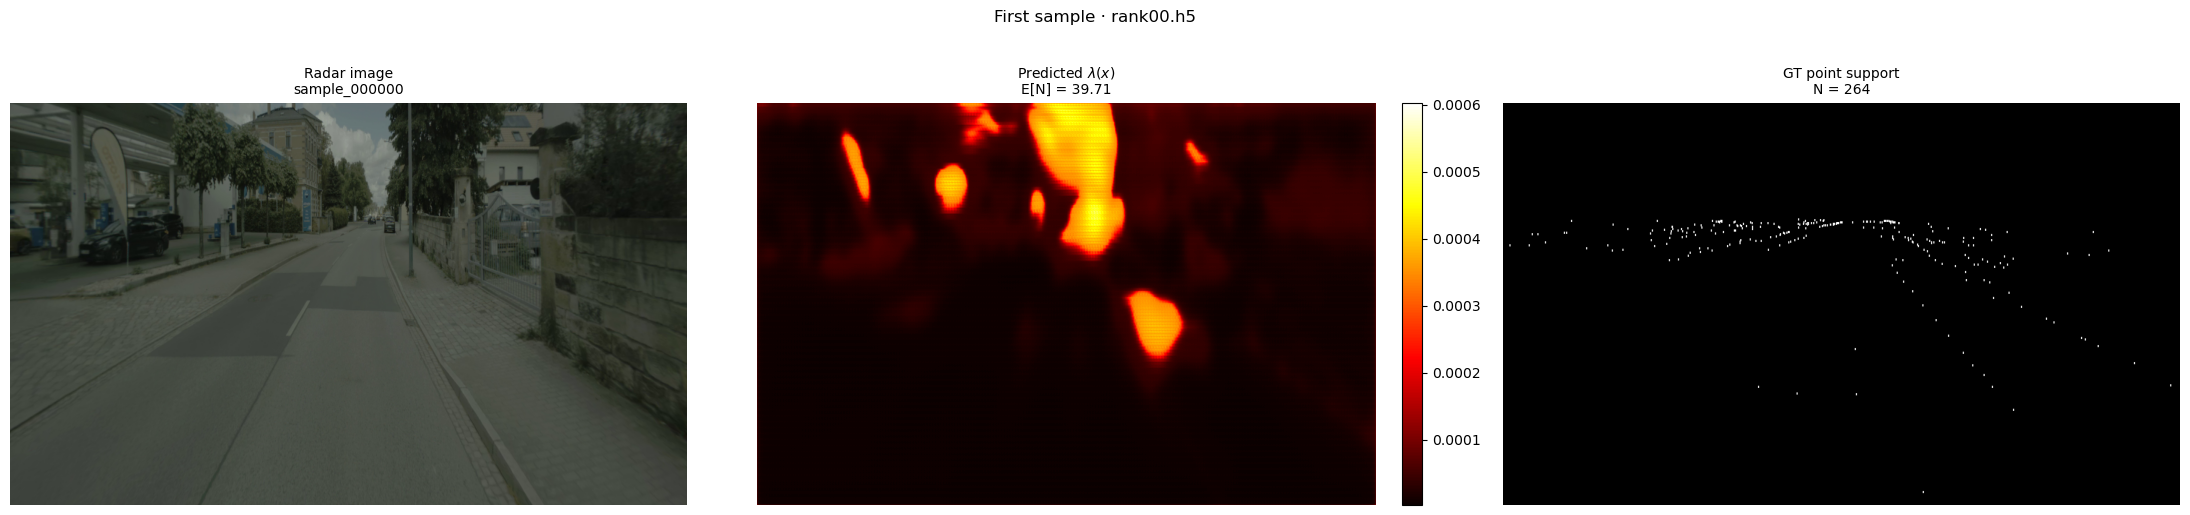

In [66]:
# Load first sample
h5_path_0, key_0 = all_samples[0]
sample = load_h5_sample(h5_path_0, key_0)

img         = sample["img"]
pred_lambda = sample["pred_lambda"]
gt_support  = sample["gt_support"]   # original – untouched
ppp         = sample["ppp"]
meta        = sample["meta"]

print(f"Sample : {meta['h5_file']}  /  {meta['sample_key']}")
print(f"Shape  : img={img.shape}  pred_lambda={pred_lambda.shape}  gt_support={gt_support.shape}")
print(f"PPP    : E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}  err={ppp['count_error']:+.2f}")

# GT point coordinates (row=y, col=x)
gt_ys, gt_xs = np.where(gt_support > 0)

# --- Side-by-side plot ---
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

ax = axes[0]
ax.imshow(img, aspect="auto")
ax.set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
ax.axis("off")

ax = axes[1]
im = ax.imshow(pred_lambda, cmap="hot", aspect="auto")
ax.set_title(
    r"Predicted $\lambda(x)$"
    f"\nE[N] = {ppp['expected_count']:.2f}",
    fontsize=10,
)
ax.axis("off")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax = axes[2]
_struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
_gt_vis = binary_dilation(gt_support > 0, structure=_struct)
gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
gt_rgb[_gt_vis] = 255
ax.imshow(gt_rgb, aspect="auto")
ax.set_title(
    f"GT point support\nN = {ppp['gt_count']}",
    fontsize=10,
)
ax.axis("off")

plt.suptitle(f"First sample · {meta['h5_file']}", fontsize=12, y=1.02)


plt.tight_layout()
plt.show()

## 5 · Interactive Sample Browser

Use the slider to step through samples. Click **"Add to selection"** to mark the current sample. The selected keys are collected in `selected_samples` (printed in the cell below).

In [68]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# ── persistent selection list ────────────────────────────────────────────────
selected_samples = []   # list of (h5_file, sample_key)

# ── widgets ──────────────────────────────────────────────────────────────────
n = len(all_samples)

slider = widgets.IntSlider(
    value=0, min=0, max=n - 1, step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="600px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆  Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

lbl_status = widgets.Label(value=f"0 / {n} selected")

plot_out   = widgets.Output()
select_out = widgets.Output()


def _update_btn_label(idx):
    """Reflect whether the current sample is already in the selection."""
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)
    btn_add.value       = entry in selected_samples
    btn_add.description = "★  In selection" if btn_add.value else "☆  Add to selection"
    btn_add.button_style = "success" if btn_add.value else ""


def _render(idx):
    h5_path, key = all_samples[idx]
    sample = load_h5_sample(h5_path, key)

    img         = sample["img"]
    pred_lambda = sample["pred_lambda"]
    gt_support  = sample["gt_support"]
    ppp         = sample["ppp"]
    meta        = sample["meta"]

    gt_ys, gt_xs = np.where(gt_support > 0)

    with plot_out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(22, 5))

        axes[0].imshow(img, aspect="auto")
        axes[0].set_title(f"Radar image\n{meta['sample_key']}", fontsize=10)
        axes[0].axis("off")

        im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
        axes[1].set_title(
            r"Predicted $\lambda(x)$" + f"\nE[N] = {ppp['expected_count']:.2f}",
            fontsize=10,
        )
        axes[1].axis("off")
        plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

        _struct = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), dtype=bool)
        _gt_vis = binary_dilation(gt_support > 0, structure=_struct)
        _gt_rgb = np.zeros((*gt_support.shape, 3), dtype=np.uint8)
        _gt_rgb[_gt_vis] = 255
        axes[2].imshow(_gt_rgb, aspect="auto")
        axes[2].set_title(
            f"GT support\nN = {ppp['gt_count']}",
            fontsize=10,
        )
        axes[2].axis("off")

        plt.suptitle(
            f"[{idx + 1}/{n}]  {meta['h5_file']}  ·  {meta['sample_key']}"
            f"   |   E[N]={ppp['expected_count']:.2f}  GT={ppp['gt_count']}"
            f"  err={ppp['count_error']:+.2f}",
            fontsize=11, y=1.02,
        )
        plt.tight_layout()
        plt.show()


def _refresh_selection_output():
    with select_out:
        clear_output(wait=True)
        if selected_samples:
            print(f"Selected ({len(selected_samples)}):")
            for h5f, k in selected_samples:
                print(f"  {h5f}  /  {k}")
        else:
            print("No samples selected yet.")


def on_slider_change(change):
    _update_btn_label(change["new"])
    _render(change["new"])


def on_toggle_change(change):
    idx = slider.value
    h5_path, key = all_samples[idx]
    entry = (os.path.basename(h5_path), key)

    if change["new"]:                          # toggled ON → add
        if entry not in selected_samples:
            selected_samples.append(entry)
        btn_add.description  = "★  In selection"
        btn_add.button_style = "success"
    else:                                      # toggled OFF → remove
        if entry in selected_samples:
            selected_samples.remove(entry)
        btn_add.description  = "☆  Add to selection"
        btn_add.button_style = ""

    lbl_status.value = f"{len(selected_samples)} / {n} selected"
    _refresh_selection_output()


slider.observe(on_slider_change, names="value")
btn_add.observe(on_toggle_change, names="value")

# ── initial render ────────────────────────────────────────────────────────────
_update_btn_label(0)
_render(0)
_refresh_selection_output()

# ── layout ────────────────────────────────────────────────────────────────────
controls = widgets.HBox([slider, btn_add, lbl_status])

display(widgets.VBox([controls, plot_out, select_out]))
# ── layout ────────────────────────────────────────────────────────────────────controls = widgets.HBox([slider, btn_add, lbl_status])display(widgets.VBox([controls, plot_out, select_out]))


In [70]:
# ── Print final selection (run this cell after browsing) ─────────────────────
print(f"selected_samples = {selected_samples!r}")


selected_samples = [('rank00.h5', 'sample_000000')]


## Analysis: Visual Inspection Variance Sampling

Takes the **first sample** from `selected_samples` and draws **two independent point clouds**
from the predicted λ heatmap — one per sampling method — displayed side by side with the GT.

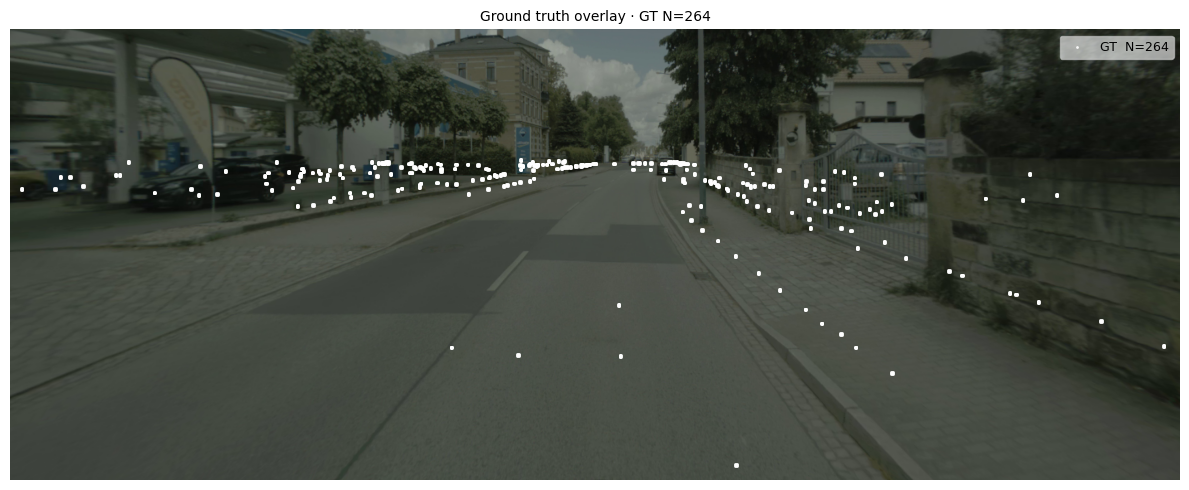

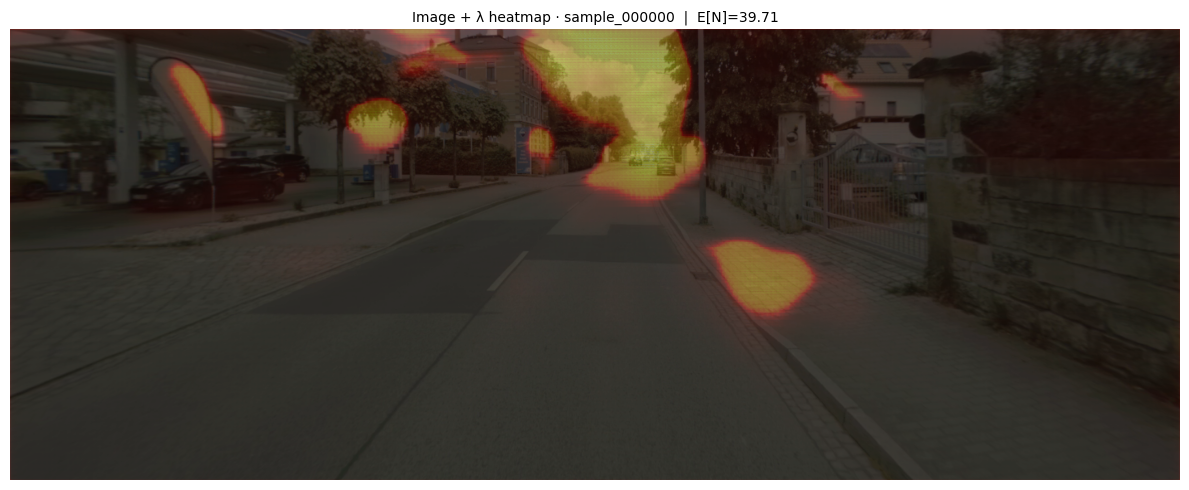

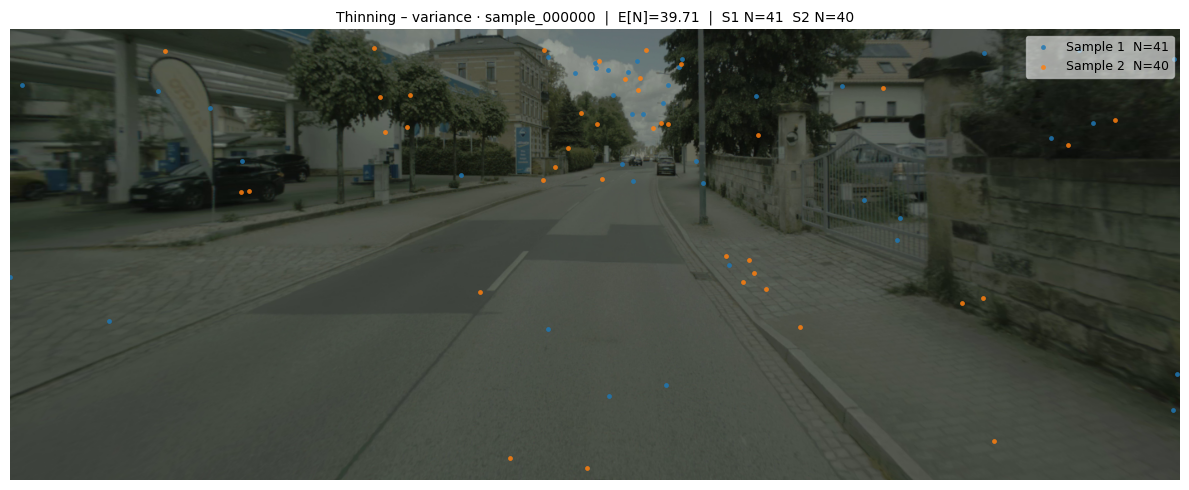

In [71]:
assert selected_samples, "No samples selected – browse and add at least one above."

# Load first selected sample
_h5_file, _key = selected_samples[0]
_h5_path = next(
    p for (p, k) in all_samples
    if os.path.basename(p) == _h5_file and k == _key
)
_sample = load_h5_sample(_h5_path, _key)

_img         = _sample["img"]
_pred_lambda = _sample["pred_lambda"]
_gt_support  = _sample["gt_support"]
_ppp         = _sample["ppp"]

H_img, W_img = _pred_lambda.shape
DOT_SIZE    = 12   # pt² for sampled points
GT_DOT_SIZE = 4    # pt² for GT points (smaller)
N_SAMPLES   = 2    # ← change this to draw more independent samples

_COLORS = plt.cm.tab10.colors  # up to 10 distinct colours

# ── N independent thinning draws ─────────────────────────────────────────────
_thin_samples = [
    sample_ppp_by_thinning(_pred_lambda, rng=np.random.default_rng(seed=i))
    for i in range(N_SAMPLES)
]

# ── shared GT coords ──────────────────────────────────────────────────────────
_struct  = np.ones((2 * GT_DILATION_RADIUS + 1, 2 * GT_DILATION_RADIUS + 1), bool)
_gt_ys, _gt_xs = np.where(binary_dilation(_gt_support > 0, structure=_struct))

# ── Plot 1: image with GT overlaid ────────────────────────────────────────────
fig_gt, ax_gt = plt.subplots(1, 1, figsize=(12, 5))
ax_gt.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
if _gt_ys.size > 0:
    ax_gt.scatter(_gt_xs, _gt_ys,
                  s=GT_DOT_SIZE, c="white", linewidths=0, alpha=0.9,
                  label=f"GT  N={_ppp['gt_count']}")
ax_gt.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_gt.axis("off")
ax_gt.set_title(f"Ground truth overlay · GT N={_ppp['gt_count']}", fontsize=10)
plt.tight_layout()
plt.show()

# ── Plot 2: image + faint lambda overlay ──────────────────────────────────────
fig_lam, ax_lam = plt.subplots(1, 1, figsize=(12, 5))
ax_lam.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
ax_lam.imshow(_pred_lambda, cmap="hot", aspect="auto",
              extent=[0, W_img, H_img, 0], alpha=0.35)
ax_lam.axis("off")
ax_lam.set_title(
    f"Image + λ heatmap · {_key}  |  E[N]={_ppp['expected_count']:.2f}",
    fontsize=10,
)
plt.tight_layout()
plt.show()

# ── Plot 3: N thinning samples overlaid on image ──────────────────────────────
fig_thin, ax_thin = plt.subplots(1, 1, figsize=(12, 5))
ax_thin.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
counts_str = []
for i, (pts, n, _, _) in enumerate(_thin_samples):
    if n > 0:
        ax_thin.scatter(pts[:, 0], pts[:, 1],
                        s=DOT_SIZE, c=[_COLORS[i % len(_COLORS)]],
                        linewidths=0, alpha=0.85,
                        label=f"Sample {i+1}  N={n}")
    counts_str.append(f"S{i+1} N={n}")
ax_thin.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_thin.axis("off")
ax_thin.set_title(
    f"Thinning – variance · {_key}  |  E[N]={_ppp['expected_count']:.2f}  |  "
    + "  ".join(counts_str),
    fontsize=10,
)
plt.tight_layout()
plt.show()


In [72]:

# ── Promote selected-sample variables for use in all downstream cells ─────────
# The interactive browser loaded the selection into _pred_lambda / _gt_support.
# Here we alias them to the unprefixed names so the projection cells below
# always operate on the interactively selected sample, not the first one loaded.
pred_lambda = _pred_lambda
gt_support  = _gt_support
img         = _img
ppp         = _ppp
H, W        = pred_lambda.shape
D           = H * W

print(f"Active sample : {_h5_file}  /  {_key}")
print(f"Shape         : pred_lambda={pred_lambda.shape}  "
      f"gt_support={gt_support.shape}")
print(f"PPP           : E[N]={ppp['expected_count']:.2f}  "
      f"GT={ppp['gt_count']}  err={ppp['count_error']:+.2f}")


Active sample : rank00.h5  /  sample_000000
Shape         : pred_lambda=(544, 1792)  gt_support=(544, 1792)
PPP           : E[N]=39.71  GT=264  err=-224.29


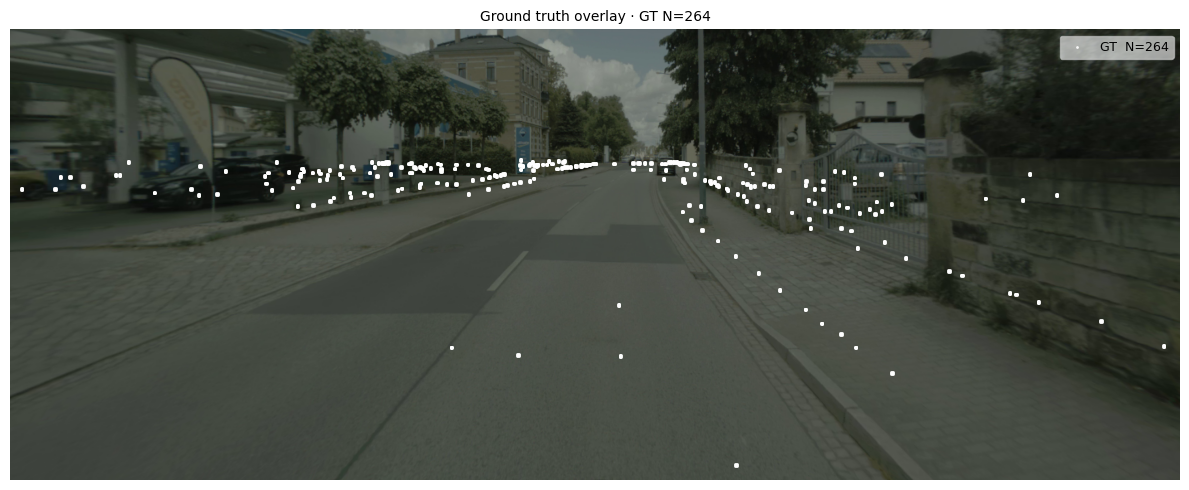

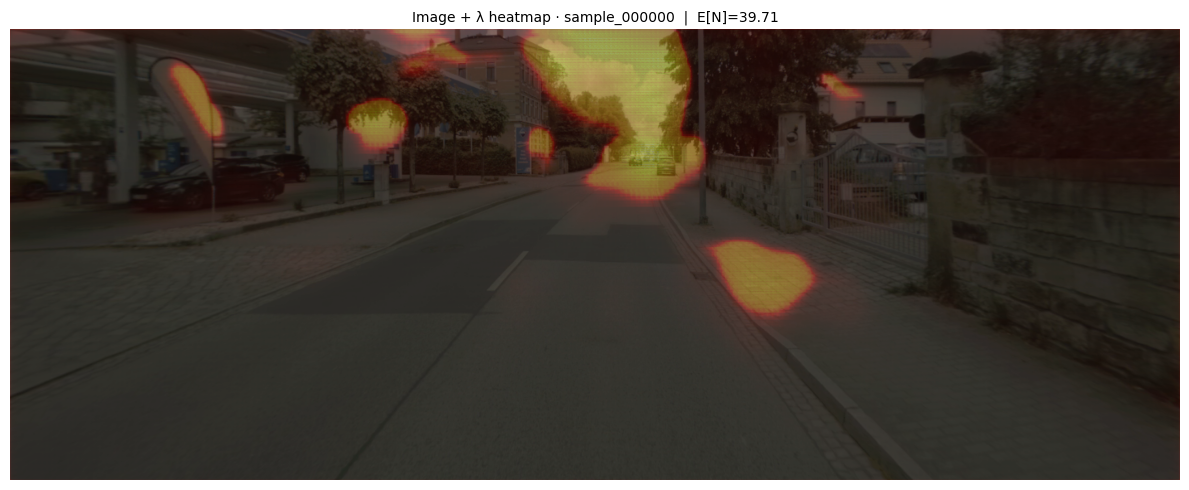

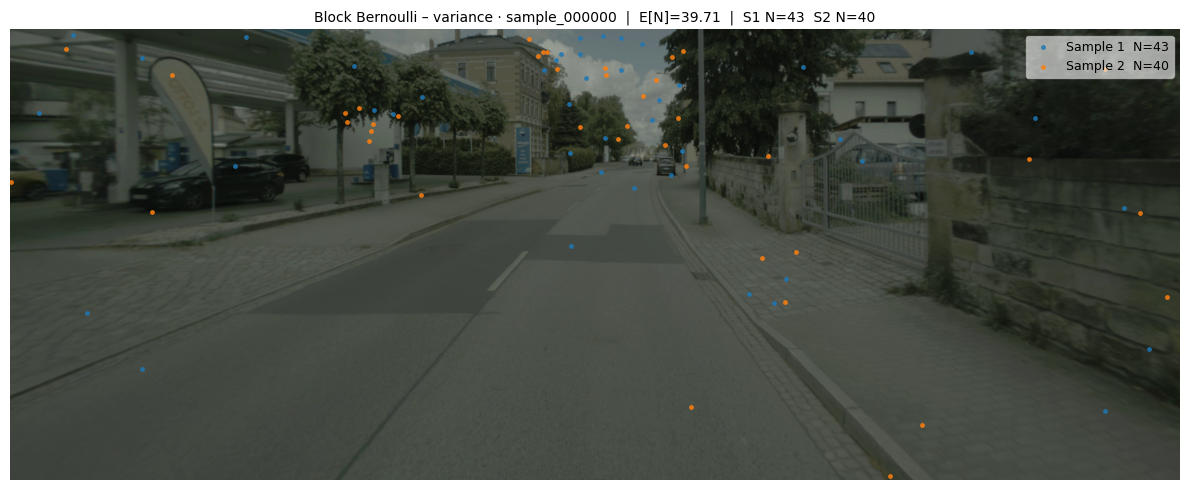

In [73]:
# ── N independent Block Bernoulli draws ──────────────────────────────────────
_bb_samples = [
    sample_points_block_bernoulli(
        _pred_lambda, block_size=8, placement="weighted",
        rng=np.random.default_rng(seed=i)
    )
    for i in range(N_SAMPLES)
]

# ── Plot 1: image with GT overlaid ────────────────────────────────────────────
fig_gt2, ax_gt2 = plt.subplots(1, 1, figsize=(12, 5))
ax_gt2.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
if _gt_ys.size > 0:
    ax_gt2.scatter(_gt_xs, _gt_ys,
                   s=GT_DOT_SIZE, c="white", linewidths=0, alpha=0.9,
                   label=f"GT  N={_ppp['gt_count']}")
ax_gt2.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_gt2.axis("off")
ax_gt2.set_title(f"Ground truth overlay · GT N={_ppp['gt_count']}", fontsize=10)
plt.tight_layout()
plt.show()

# ── Plot 2: image + faint lambda overlay ──────────────────────────────────────
fig_lam2, ax_lam2 = plt.subplots(1, 1, figsize=(12, 5))
ax_lam2.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
ax_lam2.imshow(_pred_lambda, cmap="hot", aspect="auto",
               extent=[0, W_img, H_img, 0], alpha=0.35)
ax_lam2.axis("off")
ax_lam2.set_title(
    f"Image + λ heatmap · {_key}  |  E[N]={_ppp['expected_count']:.2f}",
    fontsize=10,
)
plt.tight_layout()
plt.show()

# ── Plot 3: N block Bernoulli samples overlaid on image ───────────────────────
fig_bb, ax_bb = plt.subplots(1, 1, figsize=(12, 5))
ax_bb.imshow(_img, aspect="auto", extent=[0, W_img, H_img, 0])
counts_str = []
for i, (pts, stats) in enumerate(_bb_samples):
    n = stats["num_points"]
    if n > 0:
        ax_bb.scatter(pts[:, 0], pts[:, 1],
                      s=DOT_SIZE, c=[_COLORS[i % len(_COLORS)]],
                      linewidths=0, alpha=0.85,
                      label=f"Sample {i+1}  N={n}")
    counts_str.append(f"S{i+1} N={n}")
ax_bb.legend(loc="upper right", fontsize=9, framealpha=0.6)
ax_bb.axis("off")
ax_bb.set_title(
    f"Block Bernoulli – variance · {_key}  |  E[N]={_ppp['expected_count']:.2f}  |  "
    + "  ".join(counts_str),
    fontsize=10,
)
plt.tight_layout()
plt.show()


In [74]:
print(f"dtype      : {gt_support.dtype}")
print(f"shape      : {gt_support.shape}")
print(f"unique vals: {np.unique(gt_support)}")
print(f"min/max    : {gt_support.min():.4f} / {gt_support.max():.4f}")
print(f"nonzero px : {(gt_support > 0).sum()}")


dtype      : float32
shape      : (544, 1792)
unique vals: [0. 1.]
min/max    : 0.0000 / 1.0000
nonzero px : 264


In [75]:

# ── 5.1  Low-level helpers ───────────────────────────────────────────────────

def points_to_binary_grid(points_xy: np.ndarray, H: int, W: int) -> np.ndarray:
    """
    Convert a point cloud to a binary occupancy grid.

    Parameters
    ----------
    points_xy : (N, 2) float array
        Point coordinates in image space (x = column, y = row).
        May be empty (shape (0, 2)).
    H, W : int
        Grid dimensions.

    Returns
    -------
    grid : (H, W) float64 array with values in {0.0, 1.0}.
        Multiple points falling on the same pixel are collapsed to 1.
    """
    grid = np.zeros((H, W), dtype=np.float64)
    if points_xy.shape[0] > 0:
        xi = np.clip(points_xy[:, 0].astype(int), 0, W - 1)
        yi = np.clip(points_xy[:, 1].astype(int), 0, H - 1)
        grid[yi, xi] = 1.0
    return grid


def random_unit_vectors(
    n_projections: int,
    D: int,
    rng: np.random.Generator | None = None,
) -> np.ndarray:
    """
    Sample `n_projections` unit vectors uniformly on the unit sphere S^{D-1}.

    Method
    ------
    Draw each component i.i.d. from N(0,1) and normalise to unit length.
    This works because the standard multivariate Gaussian N(0, I_D) is
    *spherically symmetric*: the distribution of z/||z|| is uniform on S^{D-1}
    regardless of D. This is the standard and theoretically exact method.

    Numerical stability
    -------------------
    After normalisation each row has ||v||_2 = 1 to machine precision.
    The probability of drawing an all-zero vector is zero for continuous
    distributions; the guard below exists only as a safety net for extreme D.

    Parameters
    ----------
    n_projections : int
    D             : int – dimensionality (= H * W, or the active subset size)
    rng           : np.random.Generator

    Returns
    -------
    vecs : (n_projections, D) float64 array, each row has ||v||_2 == 1.
    """
    if rng is None:
        rng = np.random.default_rng()
    # i.i.d. Gaussian draws → spherically symmetric distribution
    vecs = rng.standard_normal((n_projections, D))           # (P, D)
    norms = np.linalg.norm(vecs, axis=1, keepdims=True)      # (P, 1)
    # Guard: practically impossible, but defensively replace zero norms
    zero_rows = (norms[:, 0] == 0.0)
    if zero_rows.any():
        # Resample bad rows (iterative, but will terminate in expected O(1) steps)
        while zero_rows.any():
            vecs[zero_rows] = rng.standard_normal((zero_rows.sum(), D))
            norms[zero_rows] = np.linalg.norm(vecs[zero_rows], axis=1, keepdims=True)
            zero_rows = (norms[:, 0] == 0.0)
    return vecs / norms                                       # (P, D)  unit vectors


def project_samples(
    samples_flat: np.ndarray,
    projection_vectors: np.ndarray,
) -> np.ndarray:
    """
    Project every sample onto every projection vector via dot product.

    Parameters
    ----------
    samples_flat       : (n_samples, D) float array
        Each row is a flattened binary occupancy map.
    projection_vectors : (n_projections, D) float array
        Each row is a unit vector.

    Returns
    -------
    projections : (n_samples, n_projections) float array
        projections[i, k] = <samples_flat[i], projection_vectors[k]>
    """
    return samples_flat @ projection_vectors.T              # (n, P)


def gt_quantile_per_projection(
    gt_proj: np.ndarray,
    sample_proj: np.ndarray,
) -> np.ndarray:
    """
    For each projection direction, compute the empirical quantile of the GT
    scalar projection among the scalar projections of the generated samples.

    Parameters
    ----------
    gt_proj     : (n_projections,) float array
        Scalar projection value of the single GT map.
    sample_proj : (n_samples, n_projections) float array
        Scalar projection values for each generated sample and direction.

    Returns
    -------
    quantiles : (n_projections,) float array in [0, 1]
        quantiles[k] = fraction of generated samples whose projection
        onto direction k is <= the GT projection onto direction k.
    """
    return (sample_proj <= gt_proj[np.newaxis, :]).mean(axis=0)  # (P,)


print("Helpers loaded: points_to_binary_grid, random_unit_vectors, "
      "project_samples, gt_quantile_per_projection")


Helpers loaded: points_to_binary_grid, random_unit_vectors, project_samples, gt_quantile_per_projection


In [76]:

from scipy.stats import cramervonmises

# ── Sampling function wrappers ────────────────────────────────────────────────
def _thinning_fn(lam, rng):
    pts, _, _, _ = sample_ppp_by_thinning(lam, rng=rng)
    return pts, {}

def _bb_fn(lam, rng):
    pts, stats = sample_points_block_bernoulli(
        lam, block_size=8, placement="weighted", rng=rng
    )
    return pts, stats

ACTIVE_SAMPLING_FN = _thinning_fn   # ← change here to switch everywhere

# ── 5.2  Core per-image evaluation function ──────────────────────────────────

def evaluate_single_projection(
    pred_lambda: np.ndarray,
    gt_support: np.ndarray,
    *,
    n_samples: int = 200,
    sampling_fn=None,
    rng: np.random.Generator | None = None,
) -> float:
    """
    For one (pred_lambda, gt_support) pair and one random projection direction,
    compute the empirical quantile of the GT projection among n_samples
    realizations of the predicted intensity map.

    Memory-efficient implementation: grids are generated and stored as a list
    of flat arrays. The active_mask is built incrementally to avoid allocating
    a full (n_samples, D) float64 matrix upfront (which could be ~400 MB+).
    Only active pixels are used for the projection.

    Returns
    -------
    q : float in [0, 1]
        Fraction of sampled binary maps whose scalar projection onto the
        chosen direction is ≤ the GT scalar projection.
        Under a correctly specified model, q ~ Uniform[0, 1].
    """
    if rng is None:
        rng = np.random.default_rng()
    if sampling_fn is None:
        sampling_fn = ACTIVE_SAMPLING_FN

    H, W = pred_lambda.shape
    gt_flat = gt_support.astype(np.float64).ravel()

    # ── Step 1: generate n_samples binary occupancy maps ─────────────────────
    child_seeds = rng.integers(0, 2**32, size=n_samples)
    grids = []
    active_mask = gt_flat > 0

    for seed in child_seeds:
        pts, _ = sampling_fn(pred_lambda, np.random.default_rng(int(seed)))
        grid = points_to_binary_grid(pts, H, W).ravel()
        active_mask = active_mask | (grid > 0)
        grids.append(grid)

    D_active = int(active_mask.sum())

    # ── Step 2: one random projection direction in R^{D_active} ──────────────
    v = random_unit_vectors(1, D_active, rng=rng)[0]

    # ── Step 3: project GT and each sample (active pixels only) ──────────────
    gt_proj      = gt_flat[active_mask] @ v
    sample_projs = np.array([g[active_mask] @ v for g in grids])  # (n_samples,)

    return float((sample_projs <= gt_proj).mean())


# ── 5.3  Dataset-level evaluation: mean CvM score across projections ──────────

def cramervonmises_uniform_stat(quantiles: np.ndarray) -> float:
    """
    Cramér-von Mises statistic against Uniform[0, 1].

    W² = Σ_i (q_(i) - (2i-1)/(2n))² + 1/(12n)
    where q_(1) ≤ … ≤ q_(n) are the sorted observed quantiles.
    """
    n  = len(quantiles)
    sq = np.sort(quantiles)
    i  = np.arange(1, n + 1)
    return float(np.sum((sq - (2 * i - 1) / (2 * n)) ** 2) + 1.0 / (12 * n))


def evaluate_model_cvm(
    h5_dir: str,
    *,
    n_samples: int = 200,
    n_projections: int = 20,
    sampling_fn=None,
    rng_seed: int = 0,
    max_images: int | None = None,
    verbose: bool = True,
) -> dict:
    """
    Evaluate one model directory using the projection-based mean CvM score.

    Algorithm  (optimised: sample each image once, batch all projections)
    ---------
    For each image i:
        Draw n_samples PPP realisations from pred_lambda_i  ← ONCE per image
        Build active_mask from GT ∪ all sampled grids       ← ONCE per image
        Stack grids_active  (n_samples, D_active)

        Draw ALL K projection directions at once:
            V            = (K, D_active)
            gt_projs     = gt_active @ V.T          → (K,)
            sample_projs = grids_active @ V.T        → (n_samples, K)  ← one dgemm
            all_quantiles[:, i] = (sample_projs <= gt_projs).mean(axis=0)  → (K,)

    For k = 1 … K:
        CvM_k = W²({all_quantiles[k, i]}_i)  against Uniform[0, 1]
    mean_cvm = mean(CvM_0, …, CvM_K)

    Complexity vs naive approach
    ----------------------------
    PPP draws    before: n_proj × n_images × n_samples
                 after:            n_images × n_samples        (n_proj× fewer)
    Projection   before: n_proj × n_images  separate matvecs
                 after:            n_images  single dgemm each  (BLAS-optimised)

    Returns
    -------
    dict:
        mean_cvm      : float         – mean CvM across K projections
        cvm_scores    : (K,)          – per-projection CvM statistics
        all_quantiles : (K, N_images) – all computed quantiles
        n_images, n_projections, n_samples : int
    """
    if sampling_fn is None:
        sampling_fn = ACTIVE_SAMPLING_FN

    h5_files = sorted(glob.glob(os.path.join(h5_dir, "rank*.h5")))
    samples  = list_h5_samples(h5_files)
    if max_images is not None:
        samples = samples[:max_images]

    n_images = len(samples)
    if verbose:
        print(f"  Images: {n_images}  ·  n_samples={n_samples}  "
              f"·  n_projections={n_projections}  "
              f"·  sampler={sampling_fn.__name__}")

    master_rng    = np.random.default_rng(rng_seed)
    all_quantiles = np.empty((n_projections, n_images), dtype=np.float64)

    # ── Outer loop: images  (sample once, batch-project across all K dirs) ────
    for i, (h5_path, key) in enumerate(samples):
        if verbose:
            print(f"  Image {i + 1:>4}/{n_images} ...", end="\r")

        s        = load_h5_sample(h5_path, key)
        pred_lam = s["pred_lambda"]
        gt_sup   = s["gt_support"]
        H, W     = pred_lam.shape
        gt_flat  = gt_sup.astype(np.float64).ravel()

        # ── Sample n_samples grids ONCE ───────────────────────────────────────
        child_seeds = master_rng.integers(0, 2**32, size=n_samples)
        grids       = []
        active_mask = gt_flat > 0

        for seed in child_seeds:
            pts, _ = sampling_fn(pred_lam, np.random.default_rng(int(seed)))
            grid   = points_to_binary_grid(pts, H, W).ravel()
            active_mask = active_mask | (grid > 0)
            grids.append(grid)

        gt_active    = gt_flat[active_mask]                        # (D_active,)
        grids_active = np.array([g[active_mask] for g in grids])   # (n_samples, D_active)
        D_active     = int(active_mask.sum())

        # ── Draw ALL K projection directions at once, project in one matmul ───
        V            = random_unit_vectors(n_projections, D_active, rng=master_rng)
                                                                   # (K, D_active)
        gt_projs     = gt_active @ V.T                             # (K,)
        sample_projs = grids_active @ V.T                          # (n_samples, K)
        all_quantiles[:, i] = (
            sample_projs <= gt_projs[np.newaxis, :]
        ).mean(axis=0)                                             # (K,)

    cvm_scores = np.array([
        cramervonmises_uniform_stat(all_quantiles[k])
        for k in range(n_projections)
    ])
    mean_cvm = float(cvm_scores.mean())

    if verbose:
        print(f"  Done.  mean CvM = {mean_cvm:.5f}  "
              f"(std = {cvm_scores.std():.5f} across {n_projections} projections)")

    return dict(
        mean_cvm      = mean_cvm,
        cvm_scores    = cvm_scores,
        all_quantiles = all_quantiles,
        n_images      = n_images,
        n_projections = n_projections,
        n_samples     = n_samples,
    )


print("Loaded: evaluate_single_projection, cramervonmises_uniform_stat, "
      "evaluate_model_cvm")
print(f"Active sampling fn : {ACTIVE_SAMPLING_FN.__name__}")


Loaded: evaluate_single_projection, cramervonmises_uniform_stat, evaluate_model_cvm
Active sampling fn : _thinning_fn


In [ ]:

# ── Evaluation parameters ─────────────────────────────────────────────────────
# n_samples     : number of PPP realizations sampled from pred_lambda per image
#                 per projection direction.  More → more accurate quantile.
# n_projections : number of independent random projection directions.
#                 Each gives one CvM statistic; we report their mean.
# MAX_IMAGES    : cap number of images per model (None = use all)

N_SAMPLES_EVAL     = 200   # samples drawn from pred_lambda  (accuracy vs speed)
N_PROJECTIONS_EVAL = 100    # number of projection directions (stability of mean CvM)
RNG_SEED_EVAL      = 0
MAX_IMAGES         = 100  # set e.g. to 50 for a quick test

# ── Run for every model in H5_DIRS ───────────────────────────────────────────
model_results = {}

for model_name, h5_dir in H5_DIRS.items():
    if not os.path.isdir(h5_dir):
        print(f"[SKIP] {model_name}  – directory not found:\n       {h5_dir}")
        continue

    print(f"\n{'─' * 72}")
    print(f"Model : {model_name}")

    model_results[model_name] = evaluate_model_cvm(
        h5_dir,
        n_samples     = N_SAMPLES_EVAL,
        n_projections = N_PROJECTIONS_EVAL,
        rng_seed      = RNG_SEED_EVAL,
        max_images    = MAX_IMAGES,
        verbose       = True,
    )

# ── Print ranking table ───────────────────────────────────────────────────────
print(f"\n{'═' * 80}")
print(
    f"RESULTS  ·  n_samples={N_SAMPLES_EVAL}  "
    f"n_proj={N_PROJECTIONS_EVAL}  "
    f"sampler={ACTIVE_SAMPLING_FN.__name__}"
)
print(f"{'─' * 80}")
print(f"{'Rank':<5} {'Model':<58} {'Mean CvM':>10}  {'Std CvM':>9}")
print(f"{'─' * 80}")

_ranked = sorted(
    [(n, r) for n, r in model_results.items()],
    key=lambda kv: kv[1]["mean_cvm"],
)
for rank, (name, res) in enumerate(_ranked, 1):
    short = name if len(name) <= 56 else "…" + name[-55:]
    print(
        f"  {rank}    {short:<56}  "
        f"{res['mean_cvm']:>10.5f}   "
        f"{res['cvm_scores'].std():>8.5f}"
    )



────────────────────────────────────────────────────────────────────────
Model : test_gen_data_meric_1500_13606074
  Images: 100  ·  n_samples=200  ·  n_projections=100  ·  sampler=_thinning_fn
  Done.  mean CvM = 0.67757  (std = 0.26739 across 100 projections)

────────────────────────────────────────────────────────────────────────
Model : test_gen_data_meric_13600264
  Images: 100  ·  n_samples=200  ·  n_projections=100  ·  sampler=_thinning_fn
  Done.  mean CvM = 0.18463  (std = 0.15347 across 100 projections)

────────────────────────────────────────────────────────────────────────
Model : test_gen_data_meric_1500_13603608_LR_load_model40000
  Images: 100  ·  n_samples=200  ·  n_projections=100  ·  sampler=_thinning_fn


/tmp/ipykernel_913/1853640667.py:42: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(_cvm_scores, labels=_short_names, patch_artist=True)


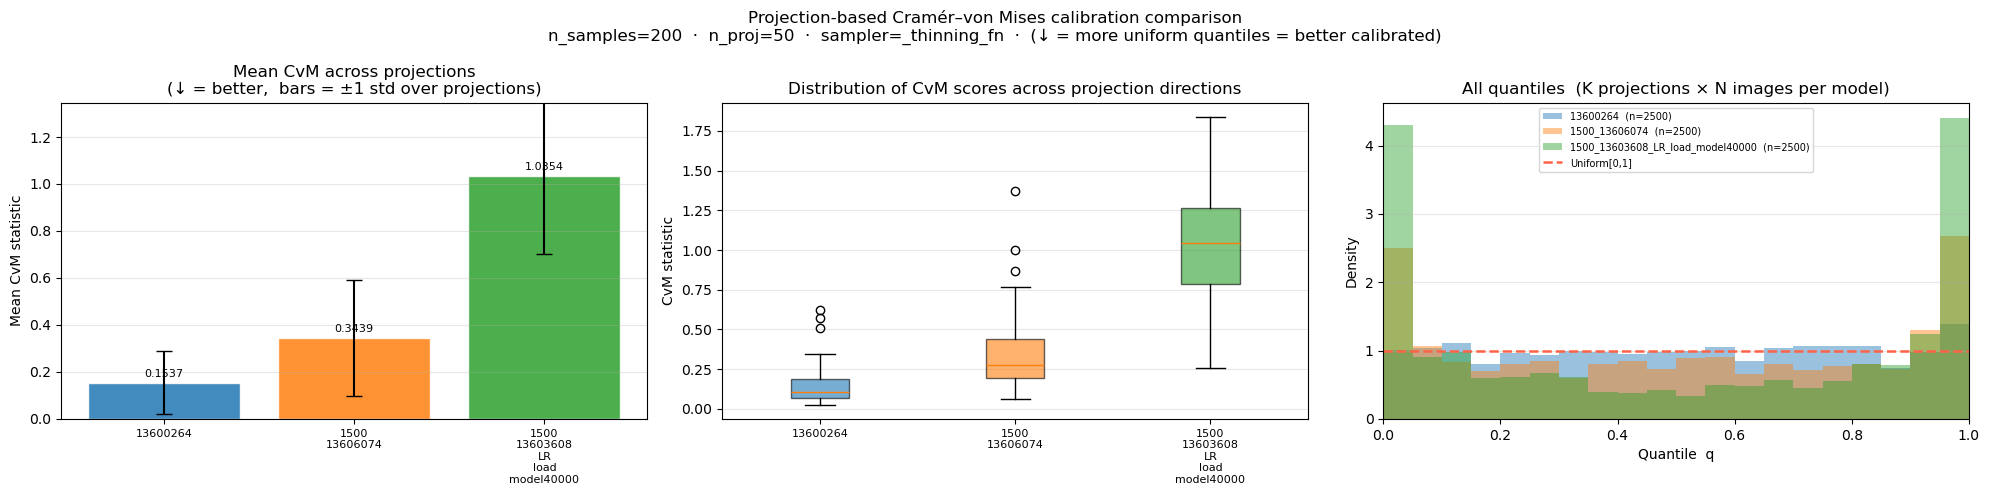

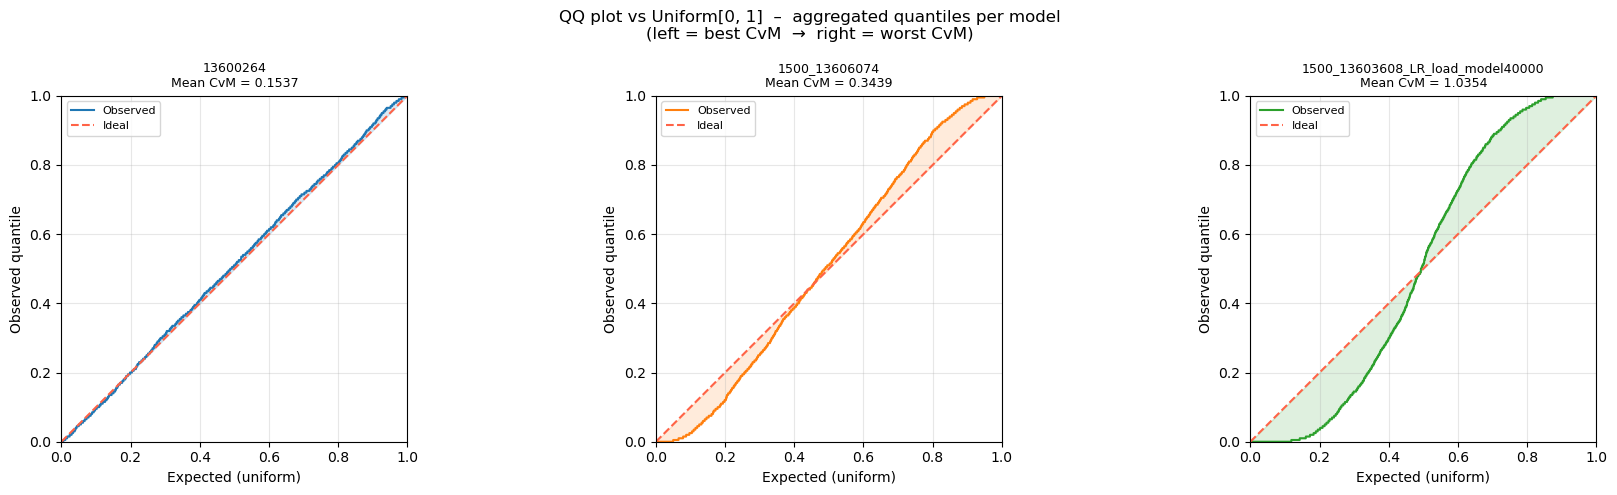

In [ ]:

# ── Visual model comparison ───────────────────────────────────────────────────

_ranked_names = [kv[0] for kv in _ranked]
_short_names  = [
    n.replace("test_gen_data_meric_", "").replace("_", "\n")
    for n in _ranked_names
]
_mean_cvms  = [model_results[n]["mean_cvm"]   for n in _ranked_names]
_cvm_scores = [model_results[n]["cvm_scores"] for n in _ranked_names]
_COLORS     = plt.cm.tab10.colors
n_models    = len(_ranked_names)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle(
    f"Projection-based Cramér–von Mises calibration comparison\n"
    f"n_samples={N_SAMPLES_EVAL}  ·  n_proj={N_PROJECTIONS_EVAL}  "
    f"·  sampler={ACTIVE_SAMPLING_FN.__name__}  "
    f"·  (↓ = more uniform quantiles = better calibrated)",
    fontsize=12,
)

# ── Panel 1: bar chart of mean CvM ───────────────────────────────────────────
ax = axes[0]
bars = ax.bar(
    range(n_models), _mean_cvms,
    color=_COLORS[:n_models], edgecolor="white", alpha=0.85,
)
ax.errorbar(
    range(n_models), _mean_cvms,
    yerr=[s.std() for s in _cvm_scores],
    fmt="none", color="black", capsize=6, linewidth=1.5,
)
ax.set_xticks(range(n_models))
ax.set_xticklabels(_short_names, fontsize=8)
ax.set_ylabel("Mean CvM statistic")
ax.set_title("Mean CvM across projections\n(↓ = better,  bars = ±1 std over projections)")
ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)
ax.set_ylim(0, max(_mean_cvms) * 1.3)
ax.grid(axis="y", alpha=0.3)

# ── Panel 2: per-projection CvM distribution (box plot) ──────────────────────
ax = axes[1]
bp = ax.boxplot(_cvm_scores, labels=_short_names, patch_artist=True)
for patch, color in zip(bp["boxes"], _COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
ax.set_ylabel("CvM statistic")
ax.set_title("Distribution of CvM scores across projection directions")
ax.set_xticklabels(_short_names, fontsize=8)
ax.grid(axis="y", alpha=0.3)

# ── Panel 3: placeholder (see separate histograms below) ─────────────────────
axes[2].set_visible(False)

plt.tight_layout()
plt.show()

# ── Separate quantile histogram per model ─────────────────────────────────────
n_bins  = 20
fig_h, axes_h = plt.subplots(1, n_models, figsize=(6 * n_models, 4), squeeze=False)
fig_h.suptitle(
    "Quantile histograms vs Uniform[0, 1]  –  one panel per model\n"
    f"(K={N_PROJECTIONS_EVAL} projections × N images per model)",
    fontsize=12,
)

for col, (name, color) in enumerate(zip(_ranked_names, _COLORS)):
    ax  = axes_h[0, col]
    res = model_results[name]
    q_all   = res["all_quantiles"].ravel()
    n_total = len(q_all)

    ax.hist(
        q_all, bins=n_bins, range=(0, 1), density=True,
        color=color, alpha=0.75, edgecolor="white",
    )
    ax.axhline(1.0, color="tomato", linewidth=1.8, linestyle="--", label="Uniform[0,1]")
    ax.set_title(
        f"{name.replace('test_gen_data_meric_', '')}\n"
        f"Mean CvM = {res['mean_cvm']:.4f}  (n={n_total})",
        fontsize=9,
    )
    ax.set_xlabel("Quantile  q")
    ax.set_ylabel("Density")
    ax.set_xlim(0, 1)
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ── QQ plots: one per model ────────────────────────────────────────────────────
fig_qq, axes_qq = plt.subplots(1, n_models, figsize=(6 * n_models, 5), squeeze=False)
fig_qq.suptitle(
    "QQ plot vs Uniform[0, 1]  –  aggregated quantiles per model\n"
    "(left = best CvM  →  right = worst CvM)",
    fontsize=12,
)

for col, (name, color) in enumerate(zip(_ranked_names, _COLORS)):
    ax    = axes_qq[0, col]
    res   = model_results[name]
    q_all = res["all_quantiles"].ravel()
    n_tot = len(q_all)
    sq    = np.sort(q_all)
    unif  = np.linspace(0, 1, n_tot)

    ax.plot(unif, sq, color=color, linewidth=1.5, label="Observed")
    ax.plot([0, 1], [0, 1], color="tomato", linewidth=1.5,
            linestyle="--", label="Ideal")
    ax.fill_between(unif, unif, sq, alpha=0.15, color=color)
    ax.set_title(
        f"{name.replace('test_gen_data_meric_', '')}\n"
        f"Mean CvM = {res['mean_cvm']:.4f}",
        fontsize=9,
    )
    ax.set_xlabel("Expected (uniform)")
    ax.set_ylabel("Observed quantile")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
